<a href="https://colab.research.google.com/github/marcelcerri/Python_biocientistas_unesp/blob/main/Aula09_Imagens.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🔬 Introdução à Análise de Imagens Aplicada à Bioquímica e Bioprocessos

Na ciência experimental, uma câmera acoplada a um microscópio ou fotodocumentador funciona como um **espectrofotômetro espacial**. Enquanto um espectrofotômetro tradicional fornece uma única leitura média de absorbância ou fluorescência da cubeta inteira, uma imagem digital realiza milhares (ou milhões) de leituras simultâneas organizadas no espaço.

Para o Python (através da biblioteca `NumPy`), uma imagem digital nada mais é do que uma **matriz numérica**:
* **Imagem em Escala de Cinza (2D):** Uma matriz de dimensões $(M \times N)$, onde $M$ é o número de linhas (altura, eixo $y$) e $N$ é o número de colunas (largura, eixo $x$). Cada posição $(y, x)$ é um **pixel** que armazena a intensidade luminosa (em imagens de 8 bits, varia de `0` = ausência total de luz/preto até `255` = saturação máxima/branco).
* **Imagem Colorida / Multicanal (3D):** Um array de dimensões $(M \times N \times C)$, onde $C$ representa os canais de cor (ex: Vermelho, Verde e Azul — RGB, ou diferentes canais de emissão na microscopia de fluorescência).

---

## Parte 1: Construindo uma Amostra Virtual de Microscopia Passo a Passo

Antes de analisar imagens reais, vamos construir nossa própria amostra biológica virtual do zero. Isso nos permite controlar exatamente o tamanho real das células, a intensidade de fluorescência e os ruídos ópticos e instrumentais.

### Etapa 1.1: O Campo Escuro e a Grade de Coordenadas (`np.zeros` e `np.ogrid`)

1. **Campo Escuro (`np.zeros`):** Se tirarmos uma foto no microscópio de fluorescência sem amostra ou com o obturador fechado, nenhum fóton atinge o sensor. Representamos essa "lâmina vazia" criando uma matriz $200 \times 200$ preenchida inteiramente com zeros.
2. **Grade de Coordenadas (`np.ogrid`):** Para desenhar células circulares sem precisar de estruturas de repetição (`for`) lentas, precisamos que cada posição da matriz saiba sua coordenada $(y, x)$. A função `np.ogrid[:200, :200]` gera dois vetores abertos:
   * `y`: um vetor-coluna vertical de dimensão $(200 \times 1)$ com os índices das linhas de `0` a `199`.
   * `x`: um vetor-linha horizontal de dimensão $(1 \times 200)$ com os índices das colunas de `0` a `199`.
   * Quando combinamos `x` e `y` em uma expressão matemática, o NumPy aplica o **broadcasting** (expansão automática), cruzando todas as linhas com todas as colunas para avaliar a equação nos $40.000$ pixels instantaneamente.

In [44]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import filters

# Garantir que o sorteio aleatório seja idêntico em todos os computadores
np.random.seed(42)

# 1. Criar a "lâmina vazia" (matriz 200x200 preenchida com zeros)
imagem_ideal = np.zeros((200, 200), dtype=np.float64)

# 2. Gerar os vetores de coordenadas y (linhas: 200x1) e x (colunas: 1x200)
y, x = np.ogrid[:200, :200]

print(f"Dimensão da matriz da imagem: {imagem_ideal.shape}")
print(f"Dimensão do vetor vertical y: {y.shape} | Dimensão do vetor horizontal x: {x.shape}")

Dimensão da matriz da imagem: (200, 200)
Dimensão do vetor vertical y: (200, 1) | Dimensão do vetor horizontal x: (1, 200)


### Etapa 1.2: Desenhando as Células com Máscaras Booleanas (`<=` e Indexação)

Uma célula esférica (como uma levedura) ou uma colônia bacteriana vista de cima projeta um círculo de raio $R$ centrado na posição $(x_0, y_0)$. Pelo Teorema de Pitágoras, a distância $d$ de qualquer pixel $(x, y)$ até o centro $(x_0, y_0)$ é:

$$d^2 = (x - x_0)^2 + (y - y_0)^2$$

Por que usamos o operador **menor ou igual (`<=`)** em vez da igualdade (`==`)?
* Se usarmos `== R**2`, selecionaremos apenas a linha exata da circunferência (um anel oco representando apenas a membrana).
* Ao usarmos a **inequação `(x - x0)**2 + (y - y0)**2 <= R**2`**, selecionamos a borda **e todo o interior do círculo** (o citoplasma inteiro).

**Como o Python processa essa linha?**
1. **Geração da Máscara Booleana:** O NumPy testa a condição `<= R**2` para todos os pixels e devolve uma matriz de $200 \times 200$ preenchida apenas com valores lógicos: `True` (onde o pixel está dentro da célula) e `False` (onde o pixel pertence ao fundo).
2. **Indexação Booleana (`imagem_ideal[celula_1] = 180.0`):** Usamos a matriz booleana como um **estêncil (máscara de pintura)**. O Python acessa a matriz `imagem_ideal` e atribui o valor de fluorescência (`180.0`, `220.0`, `150.0`) exclusivamente nos pixels onde a máscara é `True`. Na bioquímica, esses valores numéricos são diretamente proporcionais à concentração local do fluoróforo (ex: expressão de proteína verde fluorescente — GFP).

Tipo de dado da máscara 'celula_1': bool
Área teórica da Célula 1 (soma de pixels True): 1009 pixels²


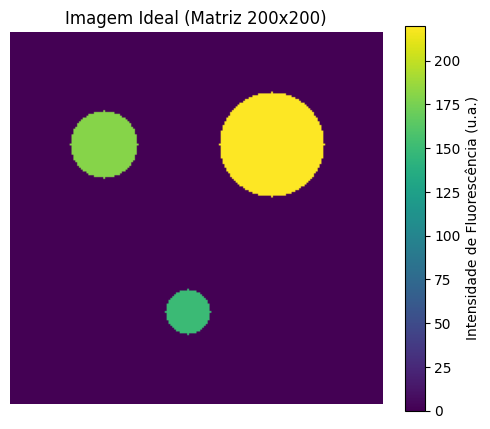

In [45]:
# Criando 3 máscaras booleanas (True dentro da célula, False no fundo)
celula_1 = (x - 50)**2 + (y - 60)**2 <= 18**2    # Centro (x=50, y=60), Raio = 18 px
celula_2 = (x - 140)**2 + (y - 60)**2 <= 28**2   # Centro (x=140, y=60), Raio = 28 px
celula_3 = (x - 95)**2 + (y - 150)**2 <= 12**2   # Centro (x=95, y=150), Raio = 12 px

# Verificando o tipo de dado da máscara booleana
print(f"Tipo de dado da máscara 'celula_1': {celula_1.dtype}")
print(f"Área teórica da Célula 1 (soma de pixels True): {np.sum(celula_1)} pixels²")

# Aplicando as máscaras para "pintar" a intensidade de fluorescência na matriz
imagem_ideal[celula_1] = 180.0  # Expressão moderada de fluorescência
imagem_ideal[celula_2] = 220.0  # Alta expressão de fluorescência
imagem_ideal[celula_3] = 150.0  # Baixa expressão de fluorescência

# Visualizando a imagem e o perfil de intensidade
plt.figure(figsize=(6, 5))
plt.imshow(imagem_ideal, cmap='viridis')
plt.colorbar(label='Intensidade de Fluorescência (u.a.)')
plt.title('Imagem Ideal (Matriz 200x200)')
plt.axis('off')
plt.show()

### Etapa 1.3: Simulando a Óptica do Microscópio (Filtro Gaussiano / Difração)

Na nossa `imagem_ideal`, a transição entre o fundo (`0`) e a célula (`180`) é um degrau matemático perfeito. Porém, em um microscópio real, a luz sofre **difração** ao atravessar as lentes objetivas (fenômeno descrito pela Função de Espalhamento de Ponto — *Point Spread Function* ou PSF).

Para simular esse efeito óptico, aplicamos um **Filtro Gaussiano** (`filters.gaussian`) com desvio padrão `sigma = 2.0`:
* Matematicamente, o filtro substitui o valor de cada pixel pela **média ponderada** dos seus vizinhos ao redor, dando maior peso aos pixels mais próximos (seguindo uma curva de distribuição Normal/Gaussiana).
* Na prática, as bordas rígidas das células tornam-se suaves e graduais, simulando com fidelidade o leve desfoque óptico natural de qualquer imagem microscópica.

---

### Etapa 1.4: Simulando o Meio de Cultura e o Detector (Ruído Normal e `np.clip`)

Em análises bioquímicas e de bioprocessos, precisamos lidar com duas fontes inevitáveis de interferência no sinal:
1. **Autofluorescência de Fundo (Linha de Base):** O meio de cultura (extrato de levedura, peptonas, sais) e a própria lâmina emitem uma leve luminescência de fundo. Portanto, o "branco" do equipamento nunca é zero absoluto, mas flutua ao redor de uma média positiva (ex: `loc = 20.0`).
2. **Ruído do Detector (Dispersão Aleatória):** A agitação térmica no sensor da câmera digital (CCD/CMOS) e a natureza quântica da chegada de fótons geram oscilações aleatórias pixel a pixel (ex: desvio padrão `scale = 15.0`).

Simulamos ambos os efeitos somando uma matriz de números aleatórios com **Distribuição Normal** (`np.random.normal`). Em seguida, aplicamos a função `np.clip(..., 0, 255)` para respeitar os limites físicos de um detector de 8 bits: valores negativos gerados pelo ruído são travados em `0`, e valores que ultrapassem a capacidade máxima do sensor são truncados em `255` (saturação).

In [46]:
# Transformação 1: Espalhamento óptico nas lentes (Desfoque Gaussiano)
# O parâmetro preserve_range=True mantém a escala original de 0 a 255
imagem_optica = filters.gaussian(imagem_ideal, sigma=2.0, preserve_range=True)

# Transformação 2: Gerar matriz de ruído de fundo (média = 20, desvio padrão = 15)
ruido_sensor = np.random.normal(loc=20.0, scale=15.0, size=imagem_ideal.shape)

# Somar a imagem óptica com o ruído e limitar à faixa física da câmera de 8 bits (0 a 255)
imagem_realista = np.clip(imagem_optica + ruido_sensor, 0, 255)

### Etapa 1.5: Inspecionando a Evolução da Matriz (Imagem 2D vs. Perfil de Linha 1D)

Para compreender o que cada transformação fez com os números da nossa matriz, vamos visualizar as três etapas lado a lado.

Além de observar a imagem 2D (linha superior), vamos traçar um **corte transversal na linha horizontal `y = 60`** (`imagem[60, :]`), que atravessa exatamente o centro das Células 1 e 2. Observe nos gráficos da linha inferior como o perfil de intensidade (espectro espacial) passa de um degrau quadrado perfeito para uma rampa suavizada e, finalmente, incorpora a linha de base e o ruído experimental:

| Etapa do Código | Operação Matemática na Matriz | Significado Físico / Biológico |
| :--- | :--- | :--- |
| `np.zeros((200, 200))` | $I(x,y) = 0$ | Campo escuro (ausência total de fluoróforo e luz de fundo). |
| `imagem[celula] = I0` | $I(x,y) = I_0 \text{ se } (x-x_0)^2+(y-y_0)^2 \le R^2$ | Distribuição espacial ideal do fluoróforo dentro do volume celular. |
| `filters.gaussian(..., sigma=2)` | Convolução com kernel Gaussiano ($G_\sigma$) | Difração da luz na lente objetiva do microscópio (suavização das bordas). |
| `+ np.random.normal(20, 15)` | $I(x,y) + \mathcal{N}(\mu=20, \sigma=15)$ | Autofluorescência do meio de cultura ($\mu=20$) + ruído térmico do sensor ($\sigma=15$). |
| `np.clip(..., 0, 255)` | $\min(\max(I, 0), 255)$ | Limites físicos do conversor analógico-digital da câmera de 8 bits. |

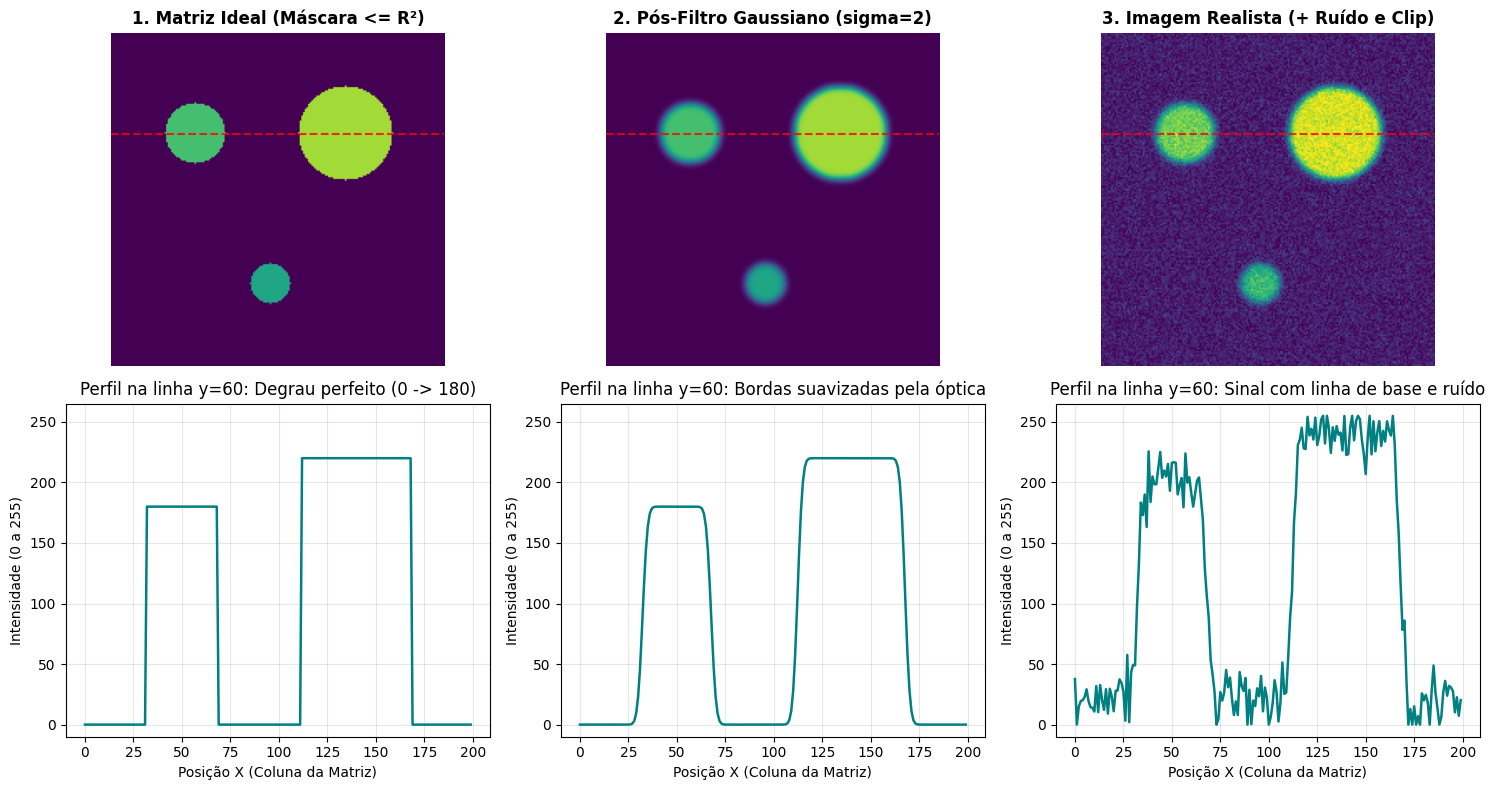

In [47]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
linha_corte = 60  # Linha horizontal que corta o centro das Células 1 e 2

estagios = [
    (imagem_ideal, "1. Matriz Ideal (Máscara <= R²)", "Degrau perfeito (0 -> 180)"),
    (imagem_optica, "2. Pós-Filtro Gaussiano (sigma=2)", "Bordas suavizadas pela óptica"),
    (imagem_realista, "3. Imagem Realista (+ Ruído e Clip)", "Sinal com linha de base e ruído")
]

for col, (img, titulo_img, titulo_perfil) in enumerate(estagios):
    # Linha superior: Visualização da Matriz 2D
    im = axes[0, col].imshow(img, cmap='viridis', vmin=0, vmax=255)
    axes[0, col].axhline(linha_corte, color='red', linestyle='--', alpha=0.8, label='Corte (y=60)')
    axes[0, col].set_title(titulo_img, fontweight='bold')
    axes[0, col].axis('off')

    # Linha inferior: Perfil de intensidade 1D ao longo da linha y = 60
    axes[1, col].plot(img[linha_corte, :], color='teal', linewidth=1.8)
    axes[1, col].set_title(f"Perfil na linha y={linha_corte}: {titulo_perfil}")
    axes[1, col].set_xlabel("Posição X (Coluna da Matriz)")
    axes[1, col].set_ylabel("Intensidade (0 a 255)")
    axes[1, col].set_ylim(-10, 265)
    axes[1, col].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

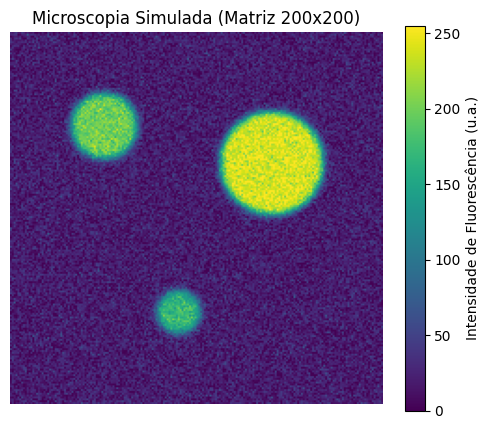

In [48]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import filters, measure, morphology

# 1. Criar o "fundo" da lâmina (matriz 200x200 preenchida com zeros)
np.random.seed(42)  # Para reprodutibilidade na aula
imagem = np.zeros((200, 200), dtype=np.float64)

# 2. Criar uma grade de coordenadas (y, x) para desenhar células circulares
y, x = np.ogrid[:200, :200]

# Inserindo 3 "células/colônias" com posições (y0, x0), raios e intensidades diferentes
# Equação do círculo: (x - x0)^2 + (y - y0)^2 <= raio^2
celula_1 = (x - 50)**2 + (y - 50)**2 <= 18**2    # Célula média
celula_2 = (x - 140)**2 + (y - 70)**2 <= 28**2   # Célula grande (ex: em divisão/agregado)
celula_3 = (x - 90)**2 + (y - 150)**2 <= 12**2   # Célula pequena

# Atribuindo intensidade de fluorescência (0 a 255)
imagem[celula_1] = 180
imagem[celula_2] = 220
imagem[celula_3] = 150

# 3. Simulando a realidade: Desfoque óptico (Gaussiano) + Ruído de fundo do sensor
imagem_realista = filters.gaussian(imagem, sigma=2)
ruido = np.random.normal(loc=20, scale=15, size=imagem.shape)
imagem_realista = np.clip(imagem_realista + ruido, 0, 255)

# Visualizando a imagem e o perfil de intensidade
plt.figure(figsize=(6, 5))
plt.imshow(imagem_realista, cmap='viridis')
plt.colorbar(label='Intensidade de Fluorescência (u.a.)')
plt.title('Microscopia Simulada (Matriz 200x200)')
plt.axis('off')
plt.show()

---

## Parte 2: O Pipeline de Recuperação e Quantificação (Da Imagem Bruta aos Dados)

Agora que temos nossa imagem realista (contendo o ruído do sensor e as bordas difusas), o desafio científico começa: **Como o computador consegue olhar para essa matriz de números e dizer exatamente quantas células existem e qual é o tamanho (área) de cada uma?**

Para resolver isso, executamos um pipeline clássico de bio-análise dividido em 4 etapas lógicas:
1. **Análise do Histograma:** Entender a distribuição estatística de todos os pixels da imagem.
2. **Segmentação por Limiar de Otsu (`threshold_otsu`):** Encontrar o ponto de corte matemático ideal para separar o "fundo" (preto/escuro) da "amostra" (células fluorescentes).
3. **Limpeza Morfológica (`remove_small_objects`):** Eliminar os resíduos de ruído aleatório que sobreviveram ao corte.
4. **Rotulagem e Extração de Propriedades (`measure.label` e `measure.regionprops`):** Agrupar pixels conectados, contar os objetos individualmente e medir suas características geométricas (área, diâmetro equivalente e intensidade média).

### Etapa 2.1: O Histograma de Intensidades e o Limiar de Otsu

Se olharmos para todos os $40.000$ pixels da nossa matriz `imagem_realista`, teremos uma distribuição de frequências:
* Um grande pico de pixels escuros com valores baixos (correspondentes ao fundo e ao ruído, ao redor de 20).
* Um segundo grupo de pixels mais claros (correspondentes aos discos das células, variando de 150 a 220).

**Como definir onde termina o fundo e começa a célula?**
Em vez de chutarmos um valor arbitrário (ex: "tudo acima de 100 é célula"), usamos o **Método de Otsu** (`filters.threshold_otsu`).
Matematicamente, o algoritmo testa todos os limiares possíveis no histograma e escolhe aquele que **minimiza a variância intra-classe** (ou seja, garante que o fundo seja o mais homogêneo possível em relação a si mesmo, e o objeto também).

Limiar de corte calculado pelo Método de Otsu: 115.05


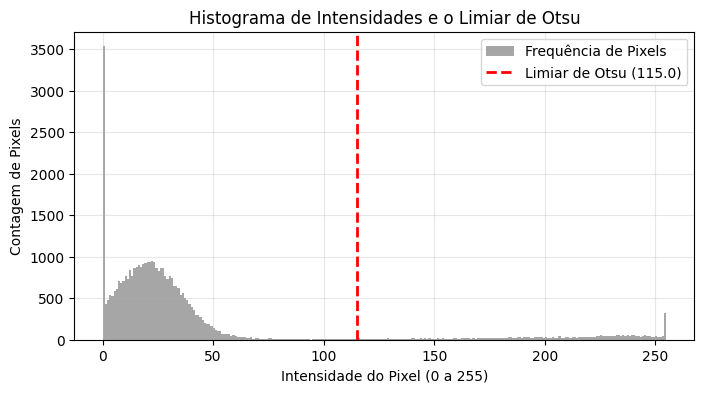

In [49]:
# 1. Calcular o Limiar de Otsu automaticamente com base no histograma da imagem
limiar_otsu = filters.threshold_otsu(imagem_realista)

print(f"Limiar de corte calculado pelo Método de Otsu: {limiar_otsu:.2f}")

# 2. Criar a Máscara Binária (True onde a imagem é mais clara que o limiar, False caso contrário)
mascara_binaria = imagem_realista > limiar_otsu

# Visualizar o histograma e o limiar de corte calculado
plt.figure(figsize=(8, 4))
plt.hist(imagem_realista.ravel(), bins=256, color='gray', alpha=0.7, label='Frequência de Pixels')
plt.axvline(limiar_otsu, color='red', linestyle='--', linewidth=2, label=f'Limiar de Otsu ({limiar_otsu:.1f})')
plt.title('Histograma de Intensidades e o Limiar de Otsu')
plt.xlabel('Intensidade do Pixel (0 a 255)')
plt.ylabel('Contagem de Pixels')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Etapa 2.2: Limpeza Morfológica e Rotulagem de Componentes Conexos

Após o corte de Otsu, a máscara binária resultante pode conter alguns pontinhos isolados (falsos positivos gerados pelo pico do ruído aleatório).

1. **Remoção de Pequenos Objetos (`remove_small_objects`):** Instruímos o Python a varrer a matriz e apagar qualquer agrupamento de pixels conectados que possua **menos de 20 pixels** de área. Como nossas células são grandes, o ruído desaparece e apenas as estruturas reais sobrevivem.
2. **Rotulagem de Componentes Conexos (`measure.label`):** O computador agora precisa responder: *"Quais pixels pertencem à Célula 1 e quais pertencem à Célula 2?"*. O algoritmo varre a matriz procurando pixels `True` que se tocam (na horizontal ou vertical). Cada grupo isolado recebe um **número de identificação único (rótulo/ID)**: `1` para o primeiro grupo, `2` para o segundo, e assim por diante.

In [50]:
from skimage import morphology, measure

# 1. Limpeza morfológica: remover aglomerados com menos de 20 pixels (elimina o ruído residual)
mascara_limpa = morphology.remove_small_objects(mascara_binaria, min_size=20)

# 2. Rotulagem: atribuir um número inteiro único para cada célula/colônia isolada
matriz_rotulada = measure.label(mascara_limpa)

# Descobrir quantas células foram detectadas na amostra
num_celulas = matriz_rotulada.max()

print(f"Total de células/colônias identificadas após a limpeza: {num_celulas}")

Total de células/colônias identificadas após a limpeza: 3


### Etapa 2.3: Extração de Atributos Bioquímicos e Geométricos (`measure.regionprops`)

Com os objetos devidamente rotulados, a função `measure.regionprops` atua como um "paquímetro digital". Passando a nossa `imagem_realista` original junto com a `matriz_rotulada`, a biblioteca extrai automaticamente diversas métricas para cada célula:

* **Área (`prop.area`):** Contagem exata de pixels que compõem o objeto (biomassa projetada).
* **Diâmetro Equivalente (`prop.equivalent_diameter_area`):** O diâmetro que o objeto teria se fosse um círculo perfeito com aquela mesma área ($\sqrt{4 \cdot \text{Área} / \pi}$).
* **Intensidade Média (`prop.mean_intensity`):** A média dos valores de brilho de todos os pixels dentro daquele objeto (indicador direto da concentração do fluoróforo ou expressão gênica).

In [51]:
# 1. Descobrir o limiar (threshold) ideal automaticamente via método de Otsu
limiar = filters.threshold_otsu(imagem_realista)
print(f"Limiar de corte calculado (Otsu): {limiar:.2f}")

# 2. Criar a máscara binária (True onde a intensidade é maior que o limiar)
mascara_binaria = imagem_realista > limiar

# Limpeza morfológica: remover pequenos pontos de ruído (< 20 pixels)
mascara_limpa = morphology.remove_small_objects(mascara_binaria, min_size=20)

# 3. Rotular os objetos conectados (identificar cada célula individualmente)
matriz_rotulada = measure.label(mascara_limpa)
num_celulas = matriz_rotulada.max()
print(f"Total de células/colônias detectadas: {num_celulas}\n")

# 4. Extrair propriedades morfométricas e ópticas de cada célula
propriedades = measure.regionprops(matriz_rotulada, intensity_image=imagem_realista)

print("-" * 65)
print(f"{'ID':<5} | {'Área (px²)':<12} | {'Diâmetro Eq. (px)':<18} | {'Fluorescência Média':<20}")
print("-" * 65)

for prop in propriedades:
    print(f"{prop.label:<5} | {prop.area:<12.0f} | {prop.equivalent_diameter_area:<18.2f} | {prop.mean_intensity:<20.2f}")

Limiar de corte calculado (Otsu): 115.05
Total de células/colônias detectadas: 3

-----------------------------------------------------------------
ID    | Área (px²)   | Diâmetro Eq. (px)  | Fluorescência Média 
-----------------------------------------------------------------
1     | 981          | 35.34              | 186.09              
2     | 2505         | 56.48              | 224.34              
3     | 379          | 21.97              | 157.79              


### Etapa 2.4: O Painel Visual Final do Processamento

Para consolidar o aprendizado da turma, vamos plotar um painel de 3 etapas que resume todo o percurso computacional:
1. **A Imagem Realista Original:** Como o sensor do microscópio enxerga o mundo.
2. **A Máscara Binária Limpa:** Onde o algoritmo decidiu matematicamente onde a amostra está (`True` em branco, fundo em preto).
3. **A Matriz Rotulada com IDs:** Onde cada célula é colorida com uma cor diferente e recebe sua identificação numérica centralizada.

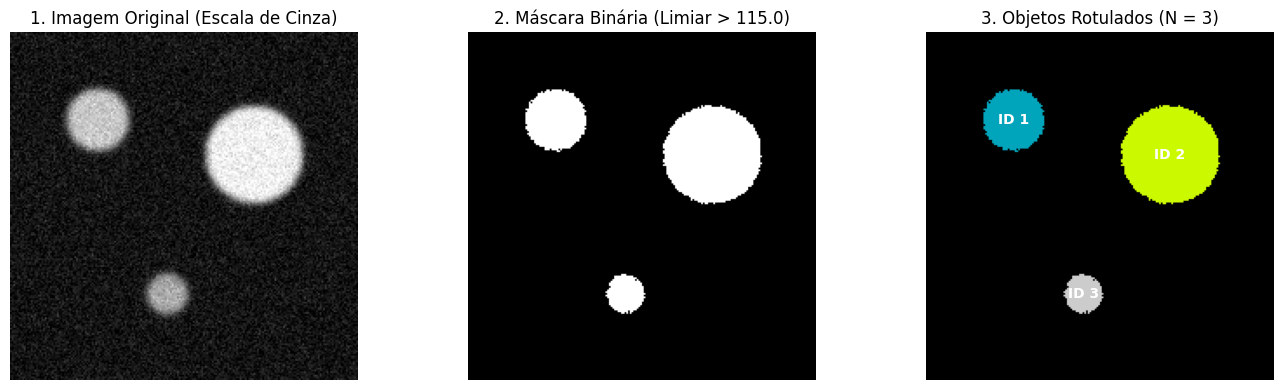

In [52]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].imshow(imagem_realista, cmap='gray')
axes[0].set_title('1. Imagem Original (Escala de Cinza)')

axes[1].imshow(mascara_limpa, cmap='binary_r')
axes[1].set_title(f'2. Máscara Binária (Limiar > {limiar:.1f})')

axes[2].imshow(matriz_rotulada, cmap='nipy_spectral')
axes[2].set_title(f'3. Objetos Rotulados (N = {num_celulas})')

# Adicionando o número de cada célula no centroide correspondente
for prop in propriedades:
    y0, x0 = prop.centroid
    axes[2].text(x0, y0, f"ID {prop.label}", color='white', fontweight='bold', ha='center', va='center')

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()

## Processando uma Foto Real de Placa de Petri (Contagem de Colônias)

Quando trabalhamos com imagens reais de laboratório (como a foto que você tirou da placa com colônias), o pipeline que usamos na simulação precisa de ajustes importantes:
1. **Iluminação Irregular (Sombras e Reflexos):** A luz do ambiente nunca é perfeitamente uniforme. O centro da placa pode ter sombras projetadas pela mão ou pela câmera, enquanto a borda reflete mais brilho. Se aplicarmos o Otsu diretamente, o algoritmo falhará nas regiões escuras.
2. **Ruídos Externos (Anotações à Caneta):** As marcações na tampa da placa ("Gabi 17/10") seriam contadas erroneamente como colônias se não limitarmos a análise estritamente à área interna do ágar.
3. **Colônias Aglomeradas:** Em algumas regiões (especialmente à esquerda e ao centro), as colônias se fundem. Trataremos isso com limiarização adaptativa e contagem de componentes.

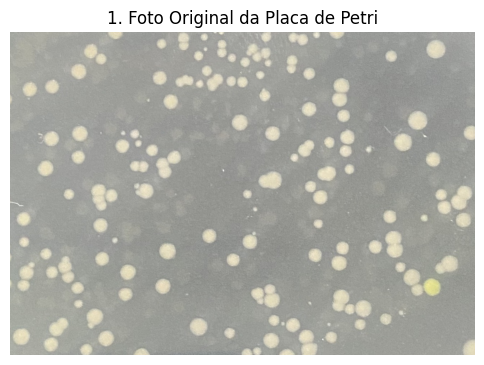

In [53]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import io, color, filters, morphology, measure, util
from skimage.restoration import denoise_tv_chambolle
import pandas as pd

# 1. Definir o caminho correto para o arquivo presente no ambiente (.jpeg)
url_imagem = "IMG_0839_tratada.jpeg"

# Carregar a matriz de pixels da imagem real usando io.imread
imagem_rgb = io.imread(url_imagem)

# 2. Converter para escala de cinza (reduzindo de 3 canais RGB para 1 canal de intensidade)
imagem_cinza = color.rgb2gray(imagem_rgb)

# Visualizar a imagem original carregada
plt.figure(figsize=(6, 6))
plt.imshow(imagem_rgb)
plt.title("1. Foto Original da Placa de Petri")
plt.axis('off')
plt.show()

## Filtrando o Fundo Externo (Detecção da Borda da Placa)

Para evitar que o fundo preto e as bordas de plástico interfiram na contagem:
1. **Binarização Grossa:** Aplicamos um limiar baixo para separar o que é a placa clara do fundo preto da mesa.
2. **Maior Componente Conexo:** Usamos `measure.label` e `regionprops` para identificar o maior objeto da imagem (que é exatamente a placa de Petri) e preenchemos seus furos com `binary_fill_holes`.
3. **Máscara de Recorte:** Multiplicamos a imagem por essa máscara circular, fazendo com que tudo o que estiver fora da placa vire preto absoluto (`0`), focando a análise estritamente no ágar.

### Correção de Iluminação de Fundo (Background Subtraction)

Como a iluminação da foto real varia do centro para as bordas, um limiar global de Otsu único para a imagem inteira deixaria escapar colônias nas áreas mais escuras.

Para resolver isso, utilizamos uma técnica de **estimativa de fundo**: aplicamos um filtro de desfoque gaussiano com um raio muito grande (`sigma alto`). Esse filtro "iguala" as sombras e o brilho do fundo, apagando as colônias pequenas. Quando subtraímos essa imagem desfocada da imagem original, o fundo da placa fica perfeitamente plano e nivelado em torno de zero, destacando apenas as colônias.

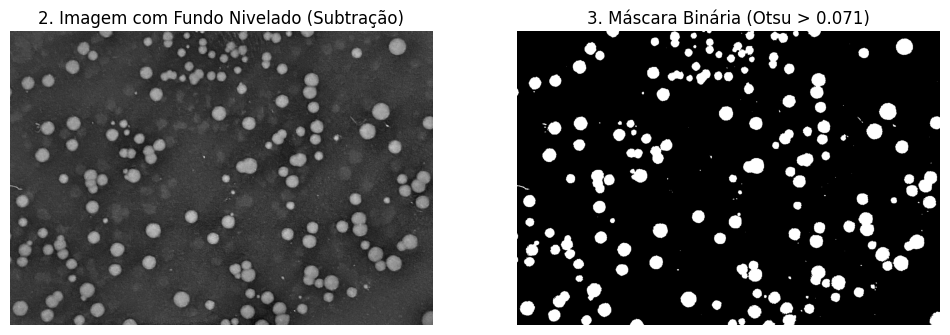

In [54]:
# 1. Estimar o fundo irregular aplicando um desfoque Gaussiano de grande raio (sigma=40)
fundo_estimado = filters.gaussian(imagem_cinza, sigma=40, preserve_range=True)

# 2. Subtrair o fundo da imagem original para nivelar a iluminação
imagem_nivelada = imagem_cinza - fundo_estimado

# 3. Aplicar o limiar de Otsu na imagem com fundo corrigido
limiar_real = filters.threshold_otsu(imagem_nivelada)
mascara_binaria = imagem_nivelada > limiar_real

# Visualizar o efeito da nivelamento e da binarização
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(imagem_nivelada, cmap='gray')
axes[0].set_title("2. Imagem com Fundo Nivelado (Subtração)")
axes[0].axis('off')

axes[1].imshow(mascara_binaria, cmap='gray')
axes[1].set_title(f"3. Máscara Binária (Otsu > {limiar_real:.3f})")
axes[1].axis('off')
plt.show()

### Limpeza de Ruídos e Contagem Automática das Colônias

Na máscara binária gerada, ainda podemos ter resíduos nas bordas do plástico da placa ou pontinhos de poeira.
* Usamos `morphology.remove_small_objects` para descartar qualquer mancha menor que o tamanho mínimo de uma colônia real.
* Em seguida, aplicamos `measure.label` para rotular cada colônia individualmente e contar o total de Unidades Formadoras de Colônias (UFC) visíveis na área de crescimento.

  CONTAGEM AUTOMÁTICA DE COLÔNIAS: 154 UFCs
Total de colônias analisadas: 154

Primeiras linhas da tabela de propriedades:


,ID_Colonia,Area_px2,Diametro_Equivalente_px,Intensidade_Media,Centro_Y,Centro_X
0,1,560.0,26.70,0.83,7.4,293.4
1,2,23.0,5.41,0.85,0.9,571.3
2,3,79.0,10.03,0.87,2.5,588.4
3,4,562.0,26.75,0.84,12.6,713.8
4,5,246.0,17.70,0.85,7.5,854.1
5,6,550.0,26.46,0.83,7.1,910.8
6,7,1147.0,38.22,0.83,24.6,483.3
7,8,1200.0,39.09,0.84,18.1,804.1
8,9,267.0,18.44,0.84,13.7,541.2
9,10,525.0,25.85,0.82,32.3,422.0


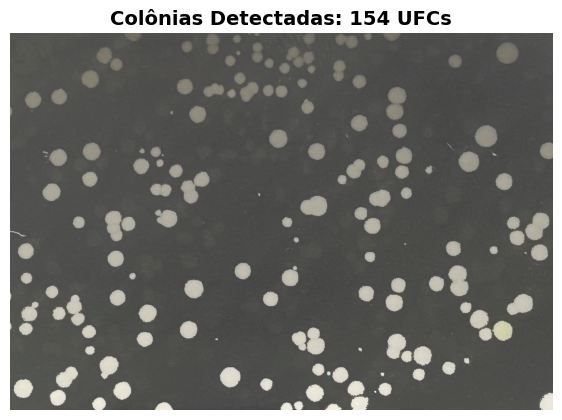

In [55]:
# 1. Remover pequenos ruídos e resíduos (ajuste o min_size conforme o tamanho real das colônias em pixels)
mascara_limpa = morphology.remove_small_objects(mascara_binaria, min_size=15)

# 2. Rotular os componentes conexos (cada colônia ganha um ID único)
matriz_rotulada = measure.label(mascara_limpa)
total_colonias = matriz_rotulada.max()

print(f"==================================================")
print(f"  CONTAGEM AUTOMÁTICA DE COLÔNIAS: {total_colonias} UFCs")
print(f"==================================================")

# 3. Extrair propriedades para medir o tamanho médio das colônias
propriedades = measure.regionprops(matriz_rotulada, intensity_image=imagem_cinza)

dados_colonias = []
for prop in propriedades:
    dados_colonias.append({
        'ID_Colonia': prop.label,
        'Area_px2': prop.area,
        'Diametro_Equivalente_px': round(prop.equivalent_diameter_area, 2),
        'Intensidade_Media': round(prop.mean_intensity, 2),
        'Centro_Y': round(prop.centroid[0], 1),
        'Centro_X': round(prop.centroid[1], 1)
    })

df_colonias = pd.DataFrame(dados_colonias)

print(f"Total de colônias analisadas: {len(df_colonias)}")
print("\nPrimeiras linhas da tabela de propriedades:")
display(df_colonias.head(15))

# 4. Painel final com as colônias identificadas e numeradas
plt.figure(figsize=(7, 7))
plt.imshow(imagem_rgb)
plt.imshow(matriz_rotulada, cmap='gray', alpha=0.5) # Sobrepõe os rótulos coloridos na foto original
plt.title(f"Colônias Detectadas: {total_colonias} UFCs", fontsize=14, fontweight='bold')
plt.axis('off')
plt.show()
